# Mancino Market: Predicting Daily Unit Sales
## Starter notebook | Business Analytics and Data Visualization
Prof. Jose Mendoza · Fall 2026

How many units will a store sell in a product category on a future day? Use the same data and evaluation process to compare KNN, a decision tree, a random forest, and a neural network. These are *regression* models: the outcome is a numeric quantity, not a class label.

Mancino Market is a synthetic grocery retailer with five fictional Manhattan stores. One row represents one date, store, and product category. Predictions can inform replenishment planning, but observed sales do not measure unmet demand during stockouts.

### How to use this notebook
1. Upload this `.ipynb` file at [Google Colab](https://colab.research.google.com/) using **File > Upload notebook**.
2. Run sections 1–5 once to prepare the data and baseline.
3. Work through sections 6–9. Change one setting at a time and rerun that model's cell. Record the validation results before changing another setting.
4. Compare models in section 10. Leave the final test switch off until you have selected your settings.
5. Complete section 11 once, then write your recommendation.

All starter code is complete. The activities focus on model settings and interpretation. No separate CSV upload is needed when the GitHub connection is available.


## 1. Import the tools
Colab includes these libraries. The notebook prints their versions so results can be traced to the environment used.


In [1]:
import io
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False,
                     'axes.spines.right': False})
print('pandas:', pd.__version__, '| scikit-learn:', sklearn.__version__)


pandas: 2.2.3 | scikit-learn: 1.6.1


## 2. Load and inspect the data
Source: [mancino_daily_sales.csv](https://github.com/jrmst102/mancino/blob/main/data/v1_2025-11-01/mancino_daily_sales.csv).
The verified file contains 22,875 rows, covering January 1–November 1, 2025. The code reports the current file dimensions in case the repository changes.

| Field | Meaning | Use in this notebook |
|---|---|---|
| `date` | Selling date | Split data and derive calendar features |
| `store_id` | Store identifier | Categorical predictor |
| `category` | Product category | Categorical predictor |
| `day_of_week` | Weekday | Recomputed from the date |
| `avg_price` | Observed daily average price | Excluded |
| `units_sold` | Daily units for a store and category | Target |
| `revenue` | Realized sales revenue | Excluded |

Revenue contains information about the sales outcome and would leak information into the model. The observed average price is also excluded because its availability before the selling day has not been established. A verified, planned price could be added in a later exercise.


In [2]:
DATA_URL = 'https://raw.githubusercontent.com/jrmst102/mancino/main/data/v1_2025-11-01/mancino_daily_sales.csv'
LOCAL_CSV = Path('mancino_daily_sales.csv')

if LOCAL_CSV.exists():
    df = pd.read_csv(LOCAL_CSV)
    print('Loaded local CSV:', LOCAL_CSV)
else:
    try:
        df = pd.read_csv(DATA_URL)
        print('Loaded CSV from GitHub.')
    except Exception as error:
        print('GitHub download failed. Upload mancino_daily_sales.csv when prompted.')
        from google.colab import files
        uploaded = files.upload()
        if 'mancino_daily_sales.csv' not in uploaded:
            raise ValueError('Please upload the named Mancino CSV.') from error
        df = pd.read_csv(io.BytesIO(uploaded['mancino_daily_sales.csv']))

required = {'date', 'store_id', 'category', 'units_sold'}
assert required.issubset(df.columns), 'The CSV is missing required columns.'
df['date'] = pd.to_datetime(df['date'], errors='raise')
assert not df[list(required)].isna().any().any(), 'Check missing required values.'
assert not df.duplicated(['date', 'store_id', 'category']).any(), 'Check duplicate rows.'
assert pd.api.types.is_numeric_dtype(df['units_sold'])
assert df['units_sold'].ge(0).all(), 'Check negative unit sales.'
df = df.sort_values(['date', 'store_id', 'category']).reset_index(drop=True)
print(f'{len(df):,} rows | {df.store_id.nunique()} stores | {df.category.nunique()} categories')
print('Dates:', df.date.min().date(), 'to', df.date.max().date())
display(df.head())
display(df.isna().sum().rename('Missing values').to_frame())


Loaded CSV from GitHub.
22,875 rows | 5 stores | 15 categories
Dates: 2025-01-01 to 2025-11-01


,date,store_id,category,avg_price,units_sold,revenue,day_of_week
0,2025-01-01,1,Alcohol,12.492667,27,330.01,Wednesday
1,2025-01-01,1,Bakery,4.123889,27,113.81,Wednesday
2,2025-01-01,1,Baking,3.749231,21,73.81,Wednesday
3,2025-01-01,1,Beverages,3.329474,31,98.61,Wednesday
4,2025-01-01,1,Breakfast & Cereal,4.950833,18,89.93,Wednesday


,Missing values
date,0
store_id,0
category,0
avg_price,0
units_sold,0
revenue,0
day_of_week,0


## 3. Define predictors and split by date
Use only information available before the selling day: store, category, weekday, and day of year. Store numbers are identifiers, so they are treated as categories. Day of year supplies a simple numeric time feature; it is not a full seasonality model.

The earliest 60% of dates form the training set, the next 20% form the validation set, and the latest 20% form the test set. Every observation from a given date stays in the same set. This asks whether patterns learned from earlier dates carry forward to later dates for the existing stores and categories.

Train on the training set, choose settings using validation results, and open the test set only after those choices are complete. This starter does not use lagged sales, promotions, or inventory data.


In [3]:
df['store_id'] = df['store_id'].astype(str)
df['weekday'] = df['date'].dt.day_name()
df['day_of_year'] = df['date'].dt.dayofyear
CATEGORICAL = ['store_id', 'category', 'weekday']
NUMERIC = ['day_of_year']
FEATURES = CATEGORICAL + NUMERIC
TARGET = 'units_sold'

dates = np.sort(df['date'].unique())
train_end = dates[int(len(dates) * 0.60) - 1]
validation_end = dates[int(len(dates) * 0.80) - 1]
train = df.loc[df.date <= train_end].copy()
validation = df.loc[(df.date > train_end) & (df.date <= validation_end)].copy()
test = df.loc[df.date > validation_end].copy()
assert train.date.max() < validation.date.min() <= validation.date.max() < test.date.min()

X_train, y_train = train[FEATURES], train[TARGET]
X_val, y_val = validation[FEATURES], validation[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]
display(pd.DataFrame([
    {'Set': name, 'Rows': len(part), 'First date': part.date.min().date(),
     'Last date': part.date.max().date()}
    for name, part in [('Training', train), ('Validation', validation), ('Test', test)]
]))


,Set,Rows,First date,Last date
0,Training,13725,2025-01-01,2025-07-02
1,Validation,4575,2025-07-03,2025-09-01
2,Test,4575,2025-09-02,2025-11-01


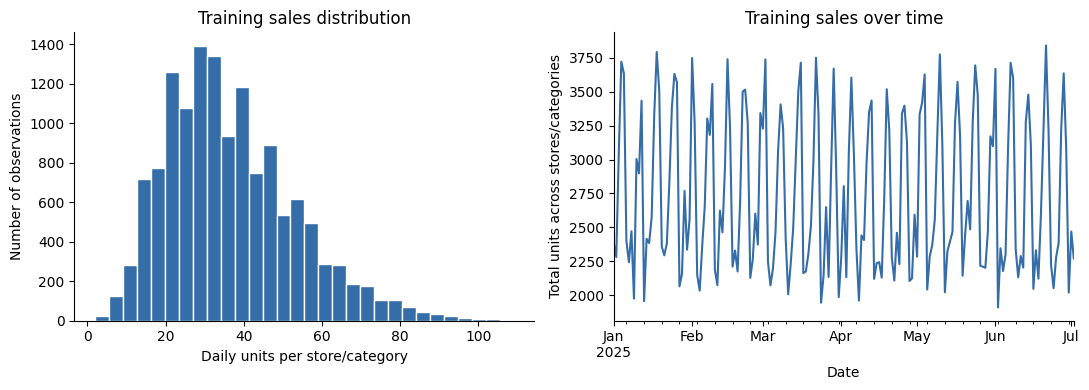

In [4]:
# Explore training outcomes only; keep later outcomes for evaluation.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(y_train, bins=30, color='#356DA8', edgecolor='white')
axes[0].set(xlabel='Daily units per store/category', ylabel='Number of observations',
            title='Training sales distribution')
train.groupby('date').units_sold.sum().plot(ax=axes[1], color='#356DA8')
axes[1].set(xlabel='Date', ylabel='Total units across stores/categories',
            title='Training sales over time')
plt.tight_layout()
plt.show()


## 4. Prepare one shared workflow
One-hot encoding turns categories into indicator columns. Scaling puts the numeric predictor on a comparable scale for KNN and the neural network. Trees do not require scaling, but can use the same transformation.

Each model gets a fresh pipeline. Encoders and scalers are fitted on the training data only, then applied to validation data without refitting.

| Metric | Interpretation | Preferred direction |
|---|---|---|
| MAE | Average absolute error, in units per store/category/day | Lower |
| RMSE | Error in units, with larger misses receiving more weight | Lower |
| R² | Performance relative to predicting the evaluation set's mean | Higher |

R² can be negative. It is not a percentage of predictions that are correct. Use validation MAE as the selection metric for this exercise.


In [5]:
def make_pipeline(estimator):
    preparation = ColumnTransformer([
        ('categories', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CATEGORICAL),
        ('numeric', StandardScaler(), NUMERIC)
    ])
    return Pipeline([('prepare', preparation), ('model', estimator)])

def metrics(actual, predicted):
    return {'MAE': mean_absolute_error(actual, predicted),
            'RMSE': np.sqrt(mean_squared_error(actual, predicted)),
            'R2': r2_score(actual, predicted)}

# Rerunning this cell clears previous model runs.
models, results = {}, {}

def fit_and_evaluate(name, estimator):
    pipeline = make_pipeline(estimator)
    started = time.perf_counter()
    pipeline.fit(X_train, y_train)
    seconds = time.perf_counter() - started
    train_scores = metrics(y_train, pipeline.predict(X_train))
    val_scores = metrics(y_val, pipeline.predict(X_val))
    models[name] = pipeline
    results[name] = {'Model': name, 'Train MAE': train_scores['MAE'],
                     'Validation MAE': val_scores['MAE'],
                     'Validation RMSE': val_scores['RMSE'],
                     'Validation R2': val_scores['R2'], 'Fit seconds': seconds}
    display(pd.DataFrame([results[name]]).round(3))
    return pipeline


## 5. Establish a baseline
The baseline always predicts the training set's mean sales. A more complicated model must earn its place by improving on this simple rule. A later extension could use historical averages for each store, category, and weekday as a stronger baseline.


In [6]:
baseline = fit_and_evaluate('Mean baseline', DummyRegressor(strategy='mean'))


,Model,Train MAE,Validation MAE,Validation RMSE,Validation R2,Fit seconds
0,Mean baseline,13.151,13.223,16.618,-0.001,0.034


## 6. Exercise A: K-nearest neighbors regression
KNN predicts from the outcomes of similar training observations. Small values of *k* follow local variation closely; larger values smooth predictions.

Run the starter with `K = 15`. Then try 5 and 50, rerunning this cell each time. Compare training and validation MAE. Which setting generalizes better? Remember that similarity depends on the encoded features and their scales.


In [7]:
K = 15                         # Try 5, 15, or 50.
knn = fit_and_evaluate('KNN', KNeighborsRegressor(n_neighbors=K, weights='uniform', n_jobs=-1))


,Model,Train MAE,Validation MAE,Validation RMSE,Validation R2,Fit seconds
0,KNN,7.559,8.741,11.33,0.535,0.026


## 7. Exercise B: Decision tree regression
A regression tree divides observations into groups and predicts the mean sales in each terminal group. Depth limits how many successive splits the tree can make.

Try `MAX_DEPTH` values of 3, 6, and 12. Does a deeper tree reduce training error more than validation error? Use the diagram to explain one decision path in business terms.


In [8]:
MAX_DEPTH = 6                  # Try 3, 6, or 12.
MIN_LEAF = 30                  # Minimum training observations in a terminal leaf.
tree = fit_and_evaluate('Decision tree', DecisionTreeRegressor(
    max_depth=MAX_DEPTH, min_samples_leaf=MIN_LEAF, random_state=SEED))


,Model,Train MAE,Validation MAE,Validation RMSE,Validation R2,Fit seconds
0,Decision tree,8.251,8.594,11.019,0.56,0.052


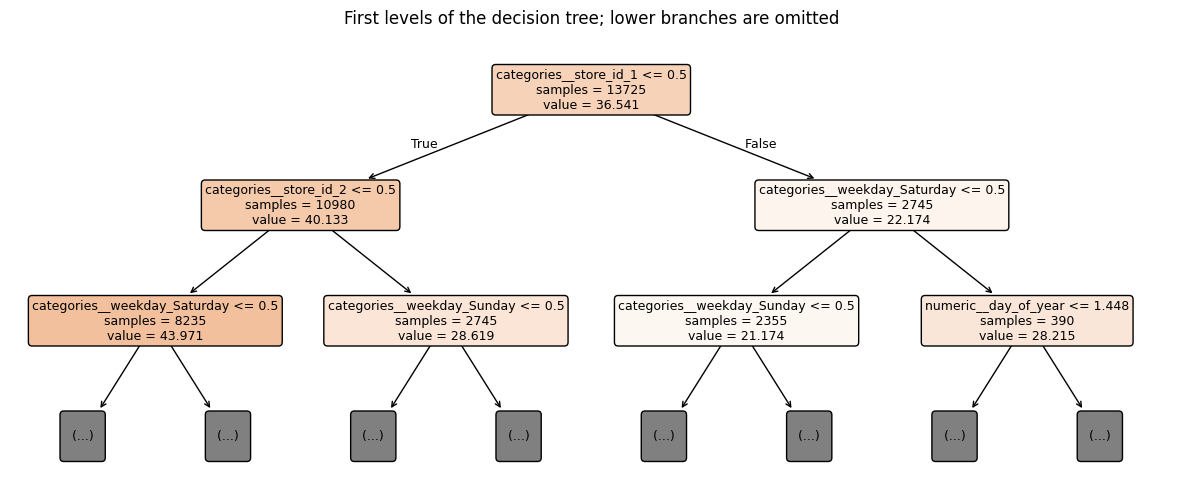

In [9]:
plt.figure(figsize=(15, 6))
plot_tree(tree.named_steps['model'], max_depth=2,
          feature_names=tree.named_steps['prepare'].get_feature_names_out(),
          filled=True, rounded=True, impurity=False, fontsize=9)
plt.title('First levels of the decision tree; lower branches are omitted')
plt.show()


## 8. Exercise C: Random forest regression
A random forest averages predictions from many trees trained with random variation in observations and candidate features. Averaging can reduce the instability of a single tree.

Try 100 and 200 trees, keeping the other settings fixed. Does any change in validation error justify the additional fitting time? Then consider changing tree depth as a separate experiment.


In [ ]:
N_TREES = 100                  # Try 100 or 200.
FOREST_DEPTH = 12
forest = fit_and_evaluate('Random forest', RandomForestRegressor(
    n_estimators=N_TREES, max_depth=FOREST_DEPTH, min_samples_leaf=10,
    max_features=0.8, random_state=SEED, n_jobs=-1))


## 9. Exercise D: Neural network regression
This multilayer perceptron combines weighted inputs through hidden layers to predict sales. The starter uses two hidden layers with 32 and 16 neurons. It runs on a CPU and does not require TensorFlow.

The wrapper scales the target during fitting and converts predictions back to units. Early stopping uses an internal random holdout drawn only from the training period. It does not use the external chronological validation or test sets; those later periods remain the generalization checks.

Compare `(16,)` with `(32, 16)`. Does the larger network improve validation MAE? If a convergence warning appears, record it and consider increasing `MAX_ITER`; do not suppress the warning.


In [ ]:
HIDDEN_LAYERS = (32, 16)       # Try (16,) or (32, 16).
MAX_ITER = 300
network_estimator = TransformedTargetRegressor(
    regressor=MLPRegressor(hidden_layer_sizes=HIDDEN_LAYERS, activation='relu',
                           solver='adam', alpha=0.01, batch_size=256,
                           learning_rate_init=0.001, max_iter=MAX_ITER,
                           early_stopping=True, validation_fraction=0.15,
                           n_iter_no_change=20, random_state=SEED),
    transformer=StandardScaler())
network = fit_and_evaluate('Neural network', network_estimator)
print('Training iterations:', network.named_steps['model'].regressor_.n_iter_)


## 10. Compare validation results
Rerun this cell after changing a model. The table keeps the most recent run for each model, so record experiments in the notes below. Restore your preferred setting and rerun its model cell before selecting a finalist.

A wide gap between training and validation MAE can indicate overfitting or a change over time. Better training performance alone does not establish a better model. These calendar features are deliberately limited, and complex models may not beat the baseline.


In [ ]:
comparison = pd.DataFrame(results.values()).sort_values('Validation MAE').reset_index(drop=True)
baseline_mae = results['Mean baseline']['Validation MAE']
comparison['MAE improvement vs baseline (%)'] = 100 * (1 - comparison['Validation MAE'] / baseline_mae)
display(comparison.round(3))
comparison.set_index('Model')['Validation MAE'].plot.barh(color='#356DA8')
plt.xlabel('Validation MAE: units per store/category/day')
plt.title('Compare errors on the same later dates')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


### Experiment notes
Double-click this cell to enter your observations. Add rows as needed.

| Model | Setting tested | Training MAE | Validation MAE | What changed? |
|---|---|---|---|---|
| KNN | | | | |
| Decision tree | | | | |
| Random forest | | | | |
| Neural network | | | | |

Which model would you select based on validation results? Would a small improvement justify a more complicated model? State your choice before opening the test set.


## 11. Final test: open only after selection
The switch below is off by default. After finishing the exercises, change it to `True`. The code selects the lowest-validation-MAE model from the current comparison, refits it on training plus validation data, and evaluates it on the untouched test period. The baseline remains eligible to win.

Do not tune settings after seeing these test results. If you do, the period becomes additional validation data and you need a new test period. Predictions are left unrounded for evaluation; fractional values represent expected units.


In [ ]:
RUN_FINAL_TEST = False        # Change to True only after you finish model selection.

if RUN_FINAL_TEST:
    required_models = {'Mean baseline', 'KNN', 'Decision tree', 'Random forest', 'Neural network'}
    assert required_models.issubset(models), 'Run all four model sections and the baseline first.'
    winner = min(results, key=lambda name: results[name]['Validation MAE'])
    X_development = pd.concat([X_train, X_val])
    y_development = pd.concat([y_train, y_val])
    final_model = clone(models[winner]).fit(X_development, y_development)
    test_predictions = final_model.predict(X_test)
    final_baseline = DummyRegressor(strategy='mean').fit(X_development, y_development)
    baseline_predictions = final_baseline.predict(X_test)
    print('Selected using validation MAE:', winner)
    display(pd.DataFrame([
        {'Model': winner, **metrics(y_test, test_predictions)},
        {'Model': 'Refitted mean baseline', **metrics(y_test, baseline_predictions)}
    ]).round(3))
    prediction_examples = test[['date', 'store_id', 'category', TARGET]].copy()
    prediction_examples['predicted_units'] = test_predictions
    prediction_examples['error_actual_minus_predicted'] = y_test.to_numpy() - test_predictions
    display(prediction_examples.head(10).round(2))
    plt.scatter(y_test, test_predictions, alpha=0.15, s=12, color='#356DA8')
    low = min(y_test.min(), test_predictions.min())
    high = max(y_test.max(), test_predictions.max())
    plt.plot([low, high], [low, high], color='#B64B44', linestyle='--')
    plt.xlabel('Actual units')
    plt.ylabel('Predicted units')
    plt.title('Final test: actual and predicted sales')
    plt.tight_layout()
    plt.show()
else:
    print('Test results remain unopened. Finish the validation exercises first.')


## 12. Business recommendation
Complete the following statements in a few sentences.

1. We selected ______ because its validation MAE was ______, compared with ______ for the baseline.
2. On the final test period, MAE was ______ units per store/category/day. This means ______ for replenishment planning.
3. One limitation is ______. Before operational use, we would add or verify ______.

The models predict observed sales. They do not establish that changing a price, promotion, or other business decision would cause a particular sales change. Stockouts can also limit observed sales. This synthetic dataset supports learning the workflow, not claims about actual retail performance.

### Sources and implementation references
- Dataset: [Mancino Market repository](https://github.com/jrmst102/mancino), maintained by Dr. Jose Mendoza; synthetic data, CC BY 4.0 according to the repository README.
- [KNeighborsRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsRegressor.html)
- [DecisionTreeRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html)
- [RandomForestRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html)
- [MLPRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPRegressor.html)
- [TransformedTargetRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.compose.TransformedTargetRegressor.html)

Prepared for the October 21, 2026 regression exercises. This notebook uses the observed CSV structure; the repository README's derived-file listing may lag behind the files currently present.
